# 🚀 Модуль 5. Урок 4. Проверка статистических гипотез: p-value, t-тест и U-критерий Манна-Уитни

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_05_statistics/lesson_04_hypothesis_testing_p_value_ttest_mann_whitney.ipynb)

## 📌 Бизнес-контекст и методология
Каждый раз, когда продуктовая команда выкатывает фичу, возникает вопрос: «Рост метрики — это реальный эффект или случайность?». 
P-value дает ответ: какова вероятность получить такую или большую разницу при условии, что никакого эффекта на самом деле нет ($H_0$).

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np

def ensure_dataset(filename, subfolder=""):
    if os.path.exists(filename):
        return filename
    candidates = [
        os.path.join("course", "datasets", subfolder, filename),
        os.path.join("course", "datasets", filename),
        os.path.join("..", "datasets", subfolder, filename),
        os.path.join("..", "datasets", filename),
        os.path.join("..", "..", "course", "datasets", subfolder, filename),
        os.path.join("datasets", subfolder, filename),
        os.path.join("datasets", filename),
    ]
    for c in candidates:
        if os.path.exists(c):
            return c
    raw_base = "https://raw.githubusercontent.com/Enlyl/data-analyst-2027/main/course/datasets"
    url = f"{raw_base}/{subfolder}/{filename}" if subfolder else f"{raw_base}/{filename}"
    urllib.request.urlretrieve(url, filename)
    return filename

ab_csv = ensure_dataset("ab_test_checkout.csv", subfolder="raw")
print("🟢 Окружение готово к анализу данных.")

🟢 Окружение готово к анализу данных.


## 🔍 Разбор механики и демонстрация на реальных данных
Сравним выручку на пользователя между контрольной (`A_Control`) и тестовой (`B_Variant`) группами с помощью t-теста Уэлча и U-критерия Манна-Уитни.

In [2]:
from scipy import stats
import pandas as pd

df_ab = pd.read_csv(ab_csv)

group_a = df_ab[df_ab['test_group'] == 'A_Control']['revenue']
group_b = df_ab[df_ab['test_group'] == 'B_Variant']['revenue']

# t-тест Уэлча
t_stat, t_pval = stats.ttest_ind(group_a, group_b, equal_var=False)

# U-критерий Манна-Уитни
u_stat, u_pval = stats.mannwhitneyu(group_a, group_b)

print(f"t-test:  t-statistic = {t_stat:.3f}, p-value = {t_pval:.4f}")
print(f"MWU-test: U-statistic = {u_stat:.1f}, p-value = {u_pval:.4f}")

t-test:  t-statistic = -0.991, p-value = 0.3219
MWU-test: U-statistic = 12406906.0, p-value = 0.1912


### 📊 Визуализация: Что такое p-value геометрически?
P-value — это площадь хвоста распределения нулевой гипотезы $H_0$ правее (и левее) наблюдаемой t-статистики. 
Если наблюдаемое значение попадает в «красную зону» отвержения ($\alpha = 0.05$), мы отвергаем $H_0$.

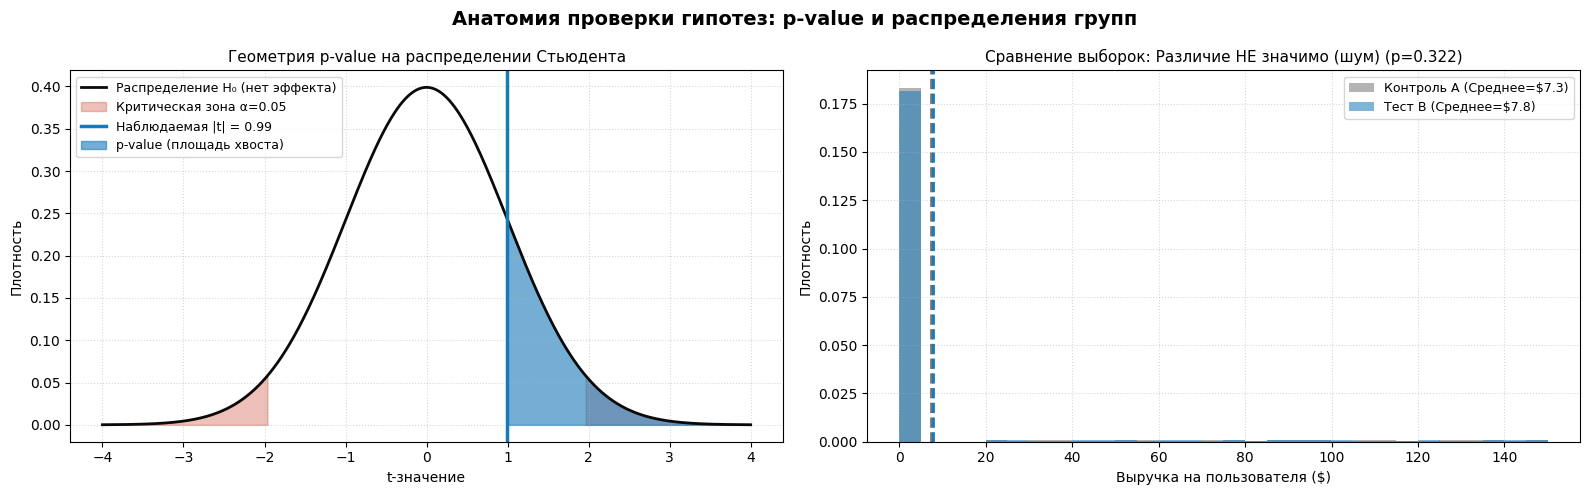

In [3]:
import matplotlib.pyplot as plt
from scipy import stats

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Анатомия проверки гипотез: p-value и распределения групп', fontsize=14, fontweight='bold')

# 1. Геометрический смысл p-value
ax1 = axes[0]
x = np.linspace(-4, 4, 500)
y = stats.norm.pdf(x)
ax1.plot(x, y, color='#0a0a0a', linewidth=2, label='Распределение H₀ (нет эффекта)')

alpha_crit = 1.96
ax1.fill_between(x[x >= alpha_crit], y[x >= alpha_crit], color='#cc4b37', alpha=0.35, label='Критическая зона α=0.05')
ax1.fill_between(x[x <= -alpha_crit], y[x <= -alpha_crit], color='#cc4b37', alpha=0.35)

t_obs = abs(t_stat)
ax1.axvline(t_obs, color='#1779ba', linewidth=2.5, linestyle='-', label=f'Наблюдаемая |t| = {t_obs:.2f}')
ax1.fill_between(x[x >= t_obs], y[x >= t_obs], color='#1779ba', alpha=0.6, label='p-value (площадь хвоста)')

ax1.set_title('Геометрия p-value на распределении Стьюдента', fontsize=11)
ax1.set_xlabel('t-значение')
ax1.set_ylabel('Плотность')
ax1.legend(loc='upper left', fontsize=9)
ax1.grid(True, linestyle=':', alpha=0.5)

# 2. Наложение распределений Группы А и Группы В
ax2 = axes[1]
ax2.hist(group_a, bins=30, alpha=0.55, color='#767676', label=f'Контроль A (Среднее=${group_a.mean():.1f})', density=True)
ax2.hist(group_b, bins=30, alpha=0.55, color='#1779ba', label=f'Тест B (Среднее=${group_b.mean():.1f})', density=True)
ax2.axvline(group_a.mean(), color='#767676', linestyle='--', linewidth=2)
ax2.axvline(group_b.mean(), color='#1779ba', linestyle='--', linewidth=2)

status_text = "Различие статистически значимо" if t_pval < 0.05 else "Различие НЕ значимо (шум)"
ax2.set_title(f'Сравнение выборок: {status_text} (p={t_pval:.3f})', fontsize=11)
ax2.set_xlabel('Выручка на пользователя ($)')
ax2.set_ylabel('Плотность')
ax2.legend(loc='upper right', fontsize=9)
ax2.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Односторонний vs Двусторонний t-тест
Проведите односторонний t-тест с альтернативой `alternative='greater'` (проверяем, что группа B строго лучше группы A).

In [4]:
### ВАШ КОД ЗДЕСЬ
t_stat_1s, t_pval_1s = stats.ttest_ind(group_b, group_a, alternative='greater', equal_var=False)

print(f"Односторонний p-value: {t_pval_1s:.4f}")
assert t_pval_1s <= 1.0, "p-value обязан быть в диапазоне [0, 1]"
print("✅ Тест успешно пройден!")

Односторонний p-value: 0.1609
✅ Тест успешно пройден!


### 💼 Когда выбирать Манна-Уитни вместо t-теста?
Если распределение сильно скошено (время сессий, количество кликов, чеки с редкими гигантскими выбросами), t-тест теряет мощность. U-критерий Манна-Уитни работает на рангах и устойчив к любым экстремальным выбросам.